# Power System Load Type Classification

## 1. Problem Understanding

**Goal:** predict the `Load_Type` of a power system: `Light_Load`, `Medium_Load` or `Maximum_Load`.

**Data:** 15-minute readings for 2018: energy usage, reactive power, CO2, power factors and time.

**Type of problem:** 3-class classification.

**Validation (from the problem statement):** the **last month (December) is the test set**.
The model is trained on January to November and evaluated on December.

**Metrics:** accuracy, precision, recall, F1-score and confusion matrix.

## 2. Import Libraries

In [1]:
# ==========================================
# CELL 1: IMPORT LIBRARIES
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Fixed random seed so results are the same every time the notebook is run
RANDOM_STATE = 42

# Class order used in reports and plots (from lowest to highest load)
LABELS = ["Light_Load", "Medium_Load", "Maximum_Load"]

## 3. Load Dataset

In [2]:
# ==========================================
# CELL 2: LOAD DATASET
# ==========================================

# Load the electricity readings so we can inspect and prepare them.
# A relative path is used so the notebook works on any machine.
# The notebook is inside the notebooks/ folder, so the data folder is one level up.
df = pd.read_csv("../data/load_data.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (35041, 9)


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


## 4. Understand Dataset

In [3]:
# ==========================================
# CELL 3: CHECK COLUMN TYPES
# ==========================================

# Check data types and how many non-empty values each column has
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Date_Time                             35041 non-null  object 
 1   Usage_kWh                             33482 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64
 4   CO2(tCO2)                             34586 non-null  float64
 5   Lagging_Current_Power_Factor          34691 non-null  float64
 6   Leading_Current_Power_Factor          33570 non-null  float64
 7   NSM                                   34586 non-null  float64
 8   Load_Type                             35041 non-null  object 
dtypes: float64(7), object(2)
memory usage: 2.4+ MB


In [4]:
# ==========================================
# CELL 4: SUMMARY STATISTICS
# ==========================================

# Min / max values help us spot impossible values (for example power factor above 100%)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Usage_kWh,33482.0,30.873061,41.415015,0.0,3.310,5.29,53.560000,435.019069
Lagging_Current_Reactive.Power_kVarh,34165.0,14.704573,20.342721,0.0,2.340,5.18,23.510000,262.630718
Leading_Current_Reactive_Power_kVarh,33885.0,4.386097,9.090181,0.0,0.000,0.00,2.298558,78.809000
CO2(tCO2),34586.0,0.012947,0.019726,0.0,0.000,0.00,0.020000,0.188166
Lagging_Current_Power_Factor,34691.0,90.740871,39.745395,0.0,66.295,90.08,100.000000,299.996814
Leading_Current_Power_Factor,33570.0,94.926552,49.826872,0.0,99.800,100.00,100.000000,299.969494
NSM,34586.0,48013.664032,34046.492333,0.0,22500.000,45000.00,68400.000000,248821.810465


In [5]:
# ==========================================
# CELL 5: CHECK MISSING VALUES
# ==========================================

# Count missing values in each column so we know what needs to be handled
print(df.isna().sum())

Date_Time                                  0
Usage_kWh                               1559
Lagging_Current_Reactive.Power_kVarh     876
Leading_Current_Reactive_Power_kVarh    1156
CO2(tCO2)                                455
Lagging_Current_Power_Factor             350
Leading_Current_Power_Factor            1471
NSM                                      455
Load_Type                                  0
dtype: int64


In [6]:
# ==========================================
# CELL 6: CHECK CLASS DISTRIBUTION
# ==========================================

# Check if the classes are balanced. If one class is much bigger,
# accuracy alone can be misleading.
print(df["Load_Type"].value_counts())
print()
print(df["Load_Type"].value_counts(normalize=True).round(3))

Light_Load      18073
Medium_Load      9696
Maximum_Load     7272
Name: Load_Type, dtype: int64

Light_Load      0.516
Medium_Load     0.277
Maximum_Load    0.208
Name: Load_Type, dtype: float64


**Observations**
- Every numeric column has missing values; the target has none.
- Power factor is a percentage, so values above 100 are impossible.
- `NSM` (seconds from midnight) should be at most 86,399, but the maximum is much higher.
- Classes are imbalanced (`Light_Load` is about half), so **macro F1** is the main metric.
  Macro F1 gives each class equal weight.

## 5. Data Cleaning

In [7]:
# ==========================================
# CELL 7: RENAME COLUMNS AND PARSE DATES
# ==========================================

# Shorter column names make the rest of the code easier to read
df = df.rename(columns={
    "Date_Time": "date_time",
    "Usage_kWh": "usage_kwh",
    "Lagging_Current_Reactive.Power_kVarh": "lagging_kvarh",
    "Leading_Current_Reactive_Power_kVarh": "leading_kvarh",
    "CO2(tCO2)": "co2",
    "Lagging_Current_Power_Factor": "lagging_pf",
    "Leading_Current_Power_Factor": "leading_pf",
    "NSM": "nsm",
    "Load_Type": "load_type",
})

# Convert text dates to real datetimes. The format is day-month-year,
# so we give it explicitly to avoid days and months being swapped.
df["date_time"] = pd.to_datetime(df["date_time"], format="%d-%m-%Y %H:%M")

print("Date range:", df["date_time"].min(), "to", df["date_time"].max())

Date range: 2018-01-01 00:00:00 to 2018-12-31 23:45:00


In [8]:
# ==========================================
# CELL 8: CHECK DUPLICATES
# ==========================================

# Exact duplicate rows would give the model the same example twice
print("Exact duplicate rows:", df.duplicated().sum())

# Each 15-minute timestamp should appear only once
print("Duplicate timestamps:", df["date_time"].duplicated().sum())

# Show the rows that share a timestamp so we can decide which one to keep
df[df["date_time"].duplicated(keep=False)]

Exact duplicate rows: 0
Duplicate timestamps: 1


,date_time,usage_kwh,lagging_kvarh,leading_kvarh,co2,lagging_pf,leading_pf,nsm,load_type
35023,2018-12-31 20:00:00,4.14,0.0,20.09,0.0,100.00000,20.18,72000.0,Light_Load
35040,2018-12-31 20:00:00,NaN,0.0,20.10,0.0,217.27347,20.19,72000.0,Light_Load


One timestamp appears twice. The second copy (last row of the file) has a missing `usage_kwh`
and an impossible power factor (217), so it looks corrupted. We keep the first copy.
This is done **before sorting**, so the original file order decides which copy is kept.

In [9]:
# ==========================================
# CELL 9: REMOVE DUPLICATE TIMESTAMP AND SORT BY TIME
# ==========================================

# Keep the first (clean) reading for the duplicated timestamp
df = df.drop_duplicates(subset="date_time", keep="first")
print("Rows after removing duplicate:", len(df))

# Some rows are out of time order (midnight readings appear after 23:45).
# Sorting matters because the train/test split and cross-validation are based on time.
out_of_order = df["date_time"].diff() < pd.Timedelta(0)
print("Rows out of time order:", out_of_order.sum())

df = df.sort_values("date_time").reset_index(drop=True)

Rows after removing duplicate: 35040
Rows out of time order: 365


In [10]:
# ==========================================
# CELL 10: FIX NSM (SECONDS FROM MIDNIGHT)
# ==========================================

# NSM should be the number of seconds since midnight for each timestamp.
# We calculate the correct value from the timestamp and compare.
correct_nsm = df["date_time"].dt.hour * 3600 + df["date_time"].dt.minute * 60

nsm_is_wrong = df["nsm"].notna() & (df["nsm"] != correct_nsm)
print("NSM missing:", df["nsm"].isna().sum())
print("NSM not matching the timestamp:", nsm_is_wrong.sum())

# The timestamp is reliable, so we replace NSM with the correct value
df["nsm"] = correct_nsm

NSM missing: 455
NSM not matching the timestamp: 3414


In [11]:
# ==========================================
# CELL 11: FIX IMPOSSIBLE POWER FACTOR VALUES
# ==========================================

# Power factor is a percentage (0-100). Values above 100 are measurement errors,
# so we mark them as missing and let the imputer fill them later.
print("lagging_pf above 100:", (df["lagging_pf"] > 100).sum())
print("leading_pf above 100:", (df["leading_pf"] > 100).sum())

df.loc[df["lagging_pf"] > 100, "lagging_pf"] = None
df.loc[df["leading_pf"] > 100, "leading_pf"] = None

lagging_pf above 100: 3225
leading_pf above 100: 2685


In [12]:
# ==========================================
# CELL 12: REMAINING MISSING VALUES
# ==========================================

# These missing values are NOT filled here.
# They are filled later with the median of the TRAINING data only (inside the pipeline),
# so no information from the test month leaks into training.
print(df.isna().sum())

date_time           0
usage_kwh        1558
lagging_kvarh     876
leading_kvarh    1156
co2               455
lagging_pf       3575
leading_pf       4156
nsm                 0
load_type           0
dtype: int64


## 6. Exploratory Data Analysis

In [13]:
# ==========================================
# CELL 13: ADD HOUR, DAY AND MONTH FOR EDA
# ==========================================

# Simple time columns used to explore patterns
df["hour"] = df["date_time"].dt.hour
df["day_of_week"] = df["date_time"].dt.dayofweek   # 0 = Monday, 6 = Sunday
df["month"] = df["date_time"].dt.month

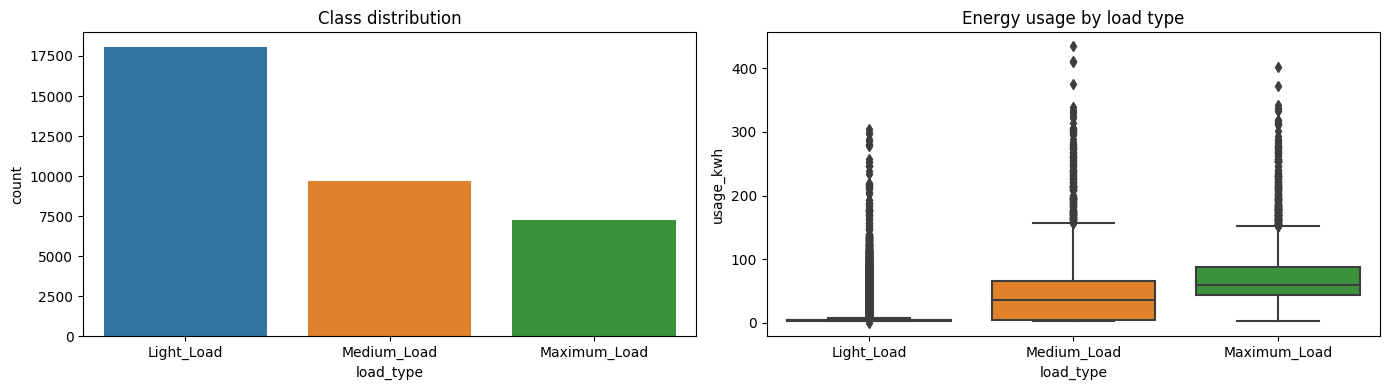

In [14]:
# ==========================================
# CELL 14: CLASS DISTRIBUTION AND ENERGY USAGE
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# How many readings belong to each class
sns.countplot(x="load_type", data=df, order=LABELS, ax=axes[0])
axes[0].set_title("Class distribution")

# Does energy usage differ between load types?
sns.boxplot(x="load_type", y="usage_kwh", data=df, order=LABELS, ax=axes[1])
axes[1].set_title("Energy usage by load type")

plt.tight_layout()
plt.show()

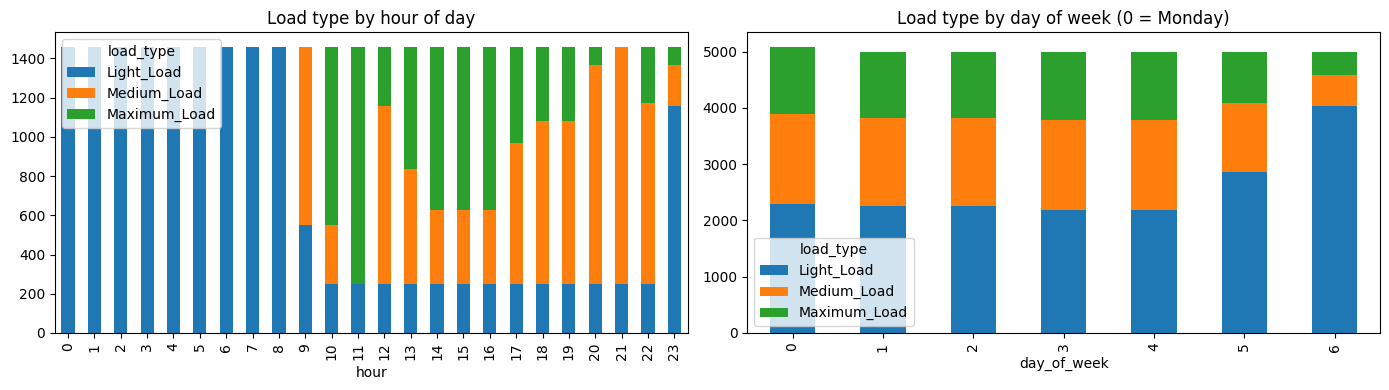

In [15]:
# ==========================================
# CELL 15: LOAD TYPE BY HOUR AND DAY OF WEEK
# ==========================================

# Count each load type per hour and per weekday to see if load follows a time schedule
counts_by_hour = pd.crosstab(df["hour"], df["load_type"])[LABELS]
counts_by_day = pd.crosstab(df["day_of_week"], df["load_type"])[LABELS]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
counts_by_hour.plot(kind="bar", stacked=True, ax=axes[0], title="Load type by hour of day")
counts_by_day.plot(kind="bar", stacked=True, ax=axes[1], title="Load type by day of week (0 = Monday)")
plt.tight_layout()
plt.show()

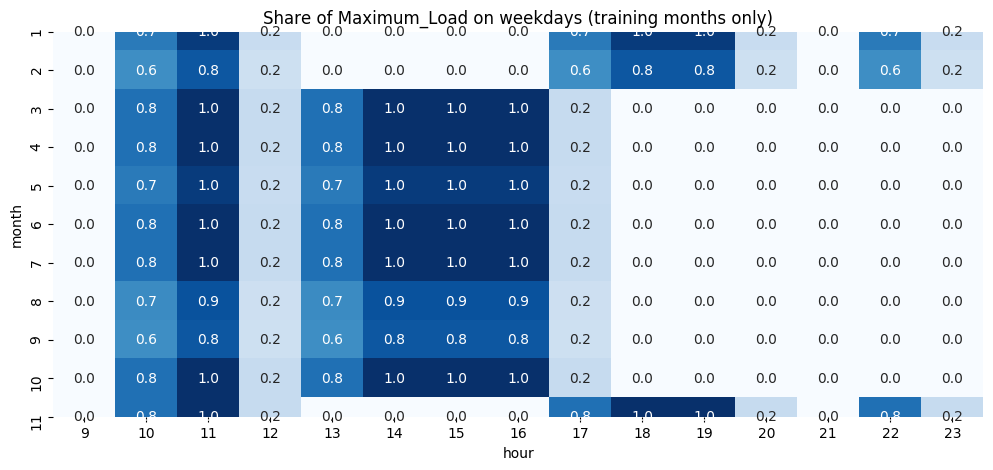

In [16]:
# ==========================================
# CELL 16: DOES THE SCHEDULE CHANGE BY MONTH?
# ==========================================

# Only weekdays from the TRAINING months (Jan-Nov) are used here,
# so the test month does not influence our feature decisions.
train_weekdays = df[(df["day_of_week"] < 5) & (df["month"] != 12)].copy()

# 1 if the reading is Maximum_Load, else 0. The mean of this column = share of Maximum_Load.
train_weekdays["is_maximum"] = (train_weekdays["load_type"] == "Maximum_Load").astype(int)

maximum_share = train_weekdays.pivot_table(index="month", columns="hour", values="is_maximum", aggfunc="mean")

# Only daytime hours are shown, because 00:00-08:59 is always Light_Load
plt.figure(figsize=(12, 5))
sns.heatmap(maximum_share.loc[:, 9:23], cmap="Blues", annot=True, fmt=".1f", cbar=False)
plt.title("Share of Maximum_Load on weekdays (training months only)")
plt.show()

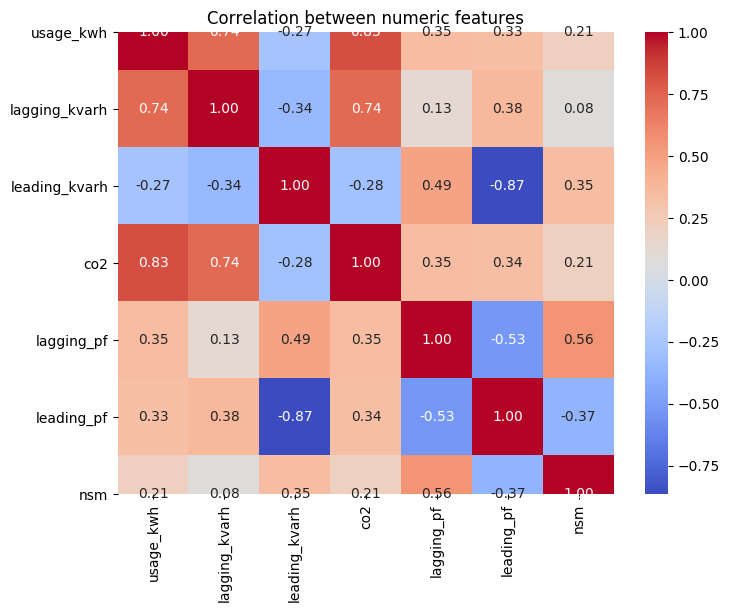

In [17]:
# ==========================================
# CELL 17: CORRELATION BETWEEN NUMERIC FEATURES
# ==========================================

# Check which features move together (strongly correlated features carry similar information)
numeric_columns = ["usage_kwh", "lagging_kvarh", "leading_kvarh", "co2", "lagging_pf", "leading_pf", "nsm"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between numeric features")
plt.show()

In [18]:
# ==========================================
# CELL 18: MEDIAN VALUES PER CLASS
# ==========================================

# Typical (median) value of each feature for each load type
df.groupby("load_type")[numeric_columns].median().loc[LABELS].T

load_type,Light_Load,Medium_Load,Maximum_Load
usage_kwh,3.42,35.93,58.90
lagging_kvarh,4.57,6.16,27.40
leading_kvarh,0.00,0.29,0.00
co2,0.00,0.02,0.03
lagging_pf,66.59,96.76,91.72
leading_pf,100.00,99.99,100.00
nsm,21600.00,65700.00,52200.00


**EDA findings**
- **Load follows a time schedule.** 00:00-08:59 is always `Light_Load`, and weekends are mostly `Light_Load`.
  The time of a reading is always known when predicting, so using it is not leakage.
- **The schedule changes in winter.** All months have `Maximum_Load` around 10:00-11:59.
  After that, January, February and November have it at 17:00-19:59 and 22:00,
  while March-October have it at 13:00-16:59 instead.
- `Medium_Load` and `Maximum_Load` use much more energy than `Light_Load`.
- `co2` is strongly correlated with `usage_kwh` (about 0.83), so it carries similar information.
  It is not target leakage, because it does not contain the load type.
- No column is created from `load_type`, so there is no direct target leakage.

## 7. Feature Engineering

In [19]:
# ==========================================
# CELL 19: FEATURE ENGINEERING
# ==========================================

# Weekends have much lower load, so we give the model a simple weekend flag
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# The EDA showed Nov-Feb follow a different schedule from Mar-Oct.
# December is treated as winter because it sits between November and January.
# Winter months exist in the training data, so the model can learn this pattern.
df["is_winter"] = df["month"].isin([11, 12, 1, 2]).astype(int)

# Features used by the model.
# - hour is not included because nsm already contains the time of day.
# - month is not included because December (12) never appears in training,
#   so the model could not learn anything from it.
features = ["usage_kwh", "lagging_kvarh", "leading_kvarh", "co2",
            "lagging_pf", "leading_pf", "nsm", "day_of_week", "is_weekend", "is_winter"]
target = "load_type"

## 8. Train/Test Split

As required: **train = January-November, test = December**.
A random split is not used, because it would let the model train on readings from after the test period.

In [20]:
# ==========================================
# CELL 20: TRAIN TEST SPLIT
# ==========================================

# Split by month: the last month (December) is the test set
is_december = df["month"] == 12
train_data = df[~is_december]
test_data = df[is_december]

X_train = train_data[features]
y_train = train_data[target]
X_test = test_data[features]
y_test = test_data[target]

print("Train:", X_train.shape, "from", train_data["date_time"].min(), "to", train_data["date_time"].max())
print("Test: ", X_test.shape, "from", test_data["date_time"].min(), "to", test_data["date_time"].max())

# Compare class balance in train and test
print()
print("Class share in train:")
print(y_train.value_counts(normalize=True).round(3))
print()
print("Class share in test:")
print(y_test.value_counts(normalize=True).round(3))

Train: (32064, 10) from 2018-01-01 00:00:00 to 2018-11-30 23:45:00
Test:  (2976, 10) from 2018-12-01 00:00:00 to 2018-12-31 23:45:00

Class share in train:
Light_Load      0.509
Medium_Load     0.280
Maximum_Load    0.210
Name: load_type, dtype: float64

Class share in test:
Light_Load      0.586
Medium_Load     0.237
Maximum_Load    0.177
Name: load_type, dtype: float64


## 9. Preprocessing and Model Training

**Preprocessing:** missing values are filled with the median, and logistic regression also needs scaling.

**Why a Pipeline?** The median (and the scaler) must be learned from training data only.
During cross-validation the training data changes in every fold, so these steps must be re-fitted in each fold.
A `Pipeline` does this automatically and prevents leakage.

**Is scaling needed?**
- Logistic Regression: yes. It is sensitive to feature size (`nsm` goes up to ~86,000, `co2` is below 1).
  An unscaled version is included to show the difference with evidence.
- Decision Tree, Random Forest, Gradient Boosting: no. Tree splits do not depend on feature scale.

**Baseline:** always predicts the most common class. Every real model must beat it.

In [21]:
# ==========================================
# CELL 21: DEFINE MODELS
# ==========================================

# Each model is a pipeline: fill missing values -> (scale) -> classifier
models = {
    "Baseline (most frequent)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="most_frequent")),
    ]),
    "Logistic Regression (no scaling)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "Logistic Regression (scaled)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]),
}

**How the models are trained and compared:** December is **not** used here.
We use `TimeSeriesSplit` cross-validation on January-November only:
each fold trains on earlier data and validates on the period right after it, like real forecasting.

In [22]:
# ==========================================
# CELL 22: CROSS-VALIDATION ON TRAINING DATA
# ==========================================

# 5 time-ordered folds: always train on the past, validate on the future
cv = TimeSeriesSplit(n_splits=5)

cv_results_list = []
for model_name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"])

    # Average the scores over the 5 folds
    cv_results_list.append({
        "model": model_name,
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_f1_macro": scores["test_f1_macro"].mean(),
        "cv_f1_macro_std": scores["test_f1_macro"].std(),
    })

In [23]:
# ==========================================
# CELL 23: CHECK THE CROSS-VALIDATION FOLDS
# ==========================================

# Print the dates in each fold to understand why some folds score lower than others
for fold_number, (train_index, validation_index) in enumerate(cv.split(X_train)):
    fold_train_end = train_data["date_time"].iloc[train_index].max().date()
    validation_start = train_data["date_time"].iloc[validation_index].min().date()
    validation_end = train_data["date_time"].iloc[validation_index].max().date()
    print("Fold", fold_number, "| train up to", fold_train_end,
          "| validate", validation_start, "to", validation_end)

Fold 0 | train up to 2018-02-25 | validate 2018-02-25 to 2018-04-22
Fold 1 | train up to 2018-04-22 | validate 2018-04-22 to 2018-06-16
Fold 2 | train up to 2018-06-16 | validate 2018-06-17 to 2018-08-11
Fold 3 | train up to 2018-08-11 | validate 2018-08-11 to 2018-10-06
Fold 4 | train up to 2018-10-06 | validate 2018-10-06 to 2018-11-30


Fold 0 trains only on January-February (winter schedule) and validates on March-April (non-winter schedule),
which the model has not seen yet. This makes the fold-to-fold spread (standard deviation) large.
Later folds contain both seasons in training.

## 10. Model Comparison

In [24]:
# ==========================================
# CELL 24: COMPARE ALL MODELS
# ==========================================

# Cross-validation results on January-November, best macro F1 first
model_results = pd.DataFrame(cv_results_list).round(3)
model_results = model_results.sort_values("cv_f1_macro", ascending=False).reset_index(drop=True)
model_results

,model,cv_accuracy,cv_f1_macro,cv_f1_macro_std
0,Gradient Boosting,0.898,0.880,0.145
1,Random Forest,0.890,0.871,0.141
2,Decision Tree,0.886,0.869,0.142
3,Logistic Regression (scaled),0.744,0.689,0.078
4,Logistic Regression (no scaling),0.676,0.617,0.079
5,Baseline (most frequent),0.501,0.223,0.005


In [25]:
# ==========================================
# CELL 25: SELECT THE BEST MODEL
# ==========================================

# The model with the highest cross-validation macro F1 is selected.
# December has not been used yet, so it stays a fair, unseen test.
best_model_name = model_results.loc[0, "model"]
print("Selected model:", best_model_name)

Selected model: Gradient Boosting


## 11. Final Model

The selected model is trained once on **all** of January-November.

In [26]:
# ==========================================
# CELL 26: TRAIN THE FINAL MODEL
# ==========================================

# Fit the selected pipeline on the full training period (Jan-Nov).
# The imputer learns its medians from this training data only.
final_model = models[best_model_name]
final_model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model', HistGradientBoostingClassifier(random_state=42))])

## 12. Evaluation on December (Test Set)

This is the first and only time December is used.
Macro averages are used so each of the 3 classes counts equally.

In [27]:
# ==========================================
# CELL 27: TEST SET METRICS
# ==========================================

# Predict the load type for every December reading
predictions = final_model.predict(X_test)

print("Model:", best_model_name)
print("Accuracy:         ", round(accuracy_score(y_test, predictions), 3))
print("Precision (macro):", round(precision_score(y_test, predictions, average="macro"), 3))
print("Recall (macro):   ", round(recall_score(y_test, predictions, average="macro"), 3))
print("F1-score (macro): ", round(f1_score(y_test, predictions, average="macro"), 3))
print()

# Precision, recall and F1 for each class
print(classification_report(y_test, predictions, labels=LABELS, digits=3))

Model: Gradient Boosting
Accuracy:          0.955
Precision (macro): 0.958
Recall (macro):    0.94
F1-score (macro):  0.949

              precision    recall  f1-score   support

  Light_Load      0.949     0.975     0.962      1744
 Medium_Load      0.967     0.946     0.956       704
Maximum_Load      0.958     0.900     0.928       528

    accuracy                          0.955      2976
   macro avg      0.958     0.940     0.949      2976
weighted avg      0.955     0.955     0.954      2976



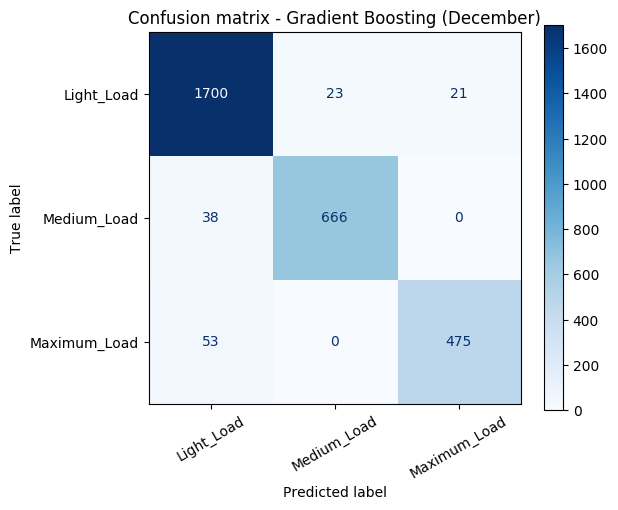

In [28]:
# ==========================================
# CELL 28: CONFUSION MATRIX
# ==========================================

# Rows = actual class, columns = predicted class. Shows which classes get mixed up.
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=LABELS, ax=ax, cmap="Blues")
ax.set_title("Confusion matrix - " + best_model_name + " (December)")
plt.xticks(rotation=30)
plt.show()

## 13. Feature Importance

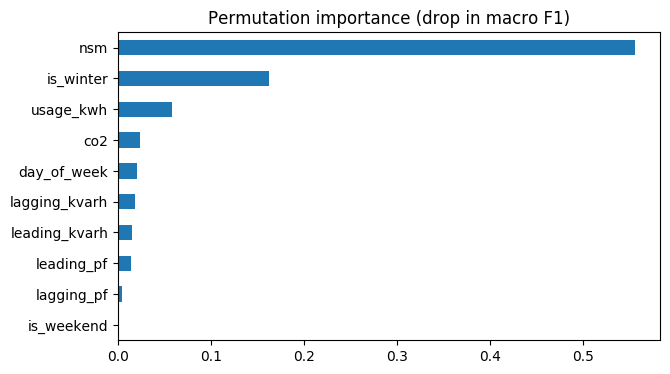

In [29]:
# ==========================================
# CELL 29: FEATURE IMPORTANCE
# ==========================================

# Permutation importance: shuffle one feature at a time and measure how much macro F1 drops.
# A big drop means the model relies on that feature.
# It is calculated on the training data because is_winter is always 1 in December,
# so shuffling it on December data would always show zero importance.
importance_result = permutation_importance(final_model, X_train, y_train, scoring="f1_macro",
                                           n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

feature_importance = pd.Series(importance_result.importances_mean, index=features).sort_values()
feature_importance.plot(kind="barh", figsize=(7, 4), title="Permutation importance (drop in macro F1)")
plt.show()

## 14. Prediction

In [30]:
# ==========================================
# CELL 30: EXAMPLE PREDICTIONS
# ==========================================

# Predict a few random December readings and compare with the actual load type
example_rows = test_data.sample(8, random_state=RANDOM_STATE)

example_predictions = pd.DataFrame({
    "date_time": example_rows["date_time"],
    "usage_kwh": example_rows["usage_kwh"],
    "actual": example_rows[target],
    "predicted": final_model.predict(example_rows[features]),
})
example_predictions

,date_time,usage_kwh,actual,predicted
34468,2018-12-26 01:00:00,3.31,Light_Load,Light_Load
34930,2018-12-30 20:30:00,3.24,Light_Load,Light_Load
34839,2018-12-29 21:45:00,3.46,Light_Load,Light_Load
32571,2018-12-06 06:45:00,3.31,Light_Load,Light_Load
33889,2018-12-20 00:15:00,4.03,Light_Load,Light_Load
33300,2018-12-13 21:00:00,20.16,Medium_Load,Medium_Load
32749,2018-12-08 03:15:00,3.96,Light_Load,Light_Load
33274,2018-12-13 14:30:00,72.61,Medium_Load,Medium_Load


In [31]:
# ==========================================
# CELL 31: FINAL SUMMARY
# ==========================================

# Summary of the final model: validation score (Jan-Nov) and test score (December)
print("Final model:", best_model_name)
print("CV macro F1 (Jan-Nov):   ", model_results.loc[0, "cv_f1_macro"])
print("Test accuracy (December):", round(accuracy_score(y_test, predictions), 3))
print("Test macro F1 (December):", round(f1_score(y_test, predictions, average="macro"), 3))

Final model: Gradient Boosting
CV macro F1 (Jan-Nov):    0.88
Test accuracy (December): 0.955
Test macro F1 (December): 0.949


## 15. Conclusion

- **Cleaning:** corrupted `NSM` recalculated from the timestamp, power factors above 100% set to missing,
  missing values filled with the training median (inside the pipeline), one corrupted duplicate removed.
- **Key insight:** load type follows a time schedule that changes between winter (Nov-Feb) and the rest of the year.
  The `is_winter` flag lets the model learn the correct schedule for December.
- **Leakage prevention:** time-based split, imputer/scaler inside a Pipeline, and model selection using
  cross-validation on January-November only. December was used once, for the final evaluation.
- **Model choice:** in cross-validation, tree-based models clearly beat the baseline and logistic regression.
  The model with the best cross-validation macro F1 was selected. Random Forest and Decision Tree are close behind,
  so a Decision Tree is a reasonable choice if explaining the rules matters more.
- **Scaling:** only helps logistic regression; tree models do not need it.
- **Limitations:** one year of data and one test month. December is assumed to follow the winter schedule.
  Most remaining errors are `Medium_Load` / `Maximum_Load` readings predicted as `Light_Load`.